# Module 7 — Pretrained Models and the Hugging Face Ecosystem

## Lesson 7.6 — Inference and Deployment Constraints


In Note 7.5 we built a sentiment service that answered sensibly on messy inputs. It ran in a notebook, on one laptop, for one person, with all the time in the world. A real feature has none of those luxuries. It must answer while the user waits, handle many users at once, fit in the memory of the machine it runs on, cost an acceptable amount, and give the same answer today as it did last month.

Those demands are **deployment constraints**, and they often decide which model you can use more than accuracy does. This note measures the main ones on our sentiment model: how long a request takes and how many requests per second we can serve, what changes on a GPU, how much memory a model needs and how to shrink it with lower-precision numbers and **quantisation**, how batching and caching save work, when to run a model yourself or use a hosted service, and how to make results reproducible.

**Key question:** *What does it take to run a pretrained model as a reliable, affordable feature, and which levers do we have?*

### Learning objectives
- measure latency and throughput, and explain why a median alone is not enough;
- explain when GPUs help, and why batching matters more on them;
- estimate a model's memory from parameters × bytes, and choose between float32, float16 and bfloat16;
- explain and implement the core idea of int8 quantisation, and measure its effect on size, accuracy and speed;
- use batching, response caching and the KV cache to avoid unnecessary computation;
- record what is needed to reproduce a model's results.

### Prerequisites

 read Notes 7.1–7.5, especially parameters × bytes (7.1, Section 6), batching and memory (7.4, Section 6) and the service from 7.5. The KV cache was introduced by name in Note 6.6.

### Setup

The usual imports, seeds and device check, and the same harmless warnings as in earlier notes. This note times things. Timings are printed with their units, and yours will differ from these, because they depend on your processor and on what else your computer is doing. Compare timings *within* your own run, not with the numbers printed here.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import io, json, time, copy, platform, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| Transformers", transformers.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1 | Transformers 5.20.1 | device: cpu


## 1. The Big Picture: From Notebook to AI Feature

A deployed model is judged on more than accuracy. Here are the constraints that come up in almost every project, and the questions behind them:

| Constraint | The question | Measured in |
|---|---|---|
| **Latency** | How long does one user wait? | milliseconds per request |
| **Throughput** | How many requests can one machine handle? | requests (examples) per second |
| **Memory** | Does the model fit on the machine? | megabytes or gigabytes |
| **Cost** | What does each request cost? | money per request or per hour |
| **Reproducibility** | Will it give the same answers next month? | pinned versions and records |

They pull against each other. A bigger model may be more accurate but slower and hungrier; batching raises throughput but makes each request wait for its batch; quantising saves memory but may cost accuracy. Engineering a feature means choosing a point among these trade-offs, and that needs measurements, which is what this note provides.

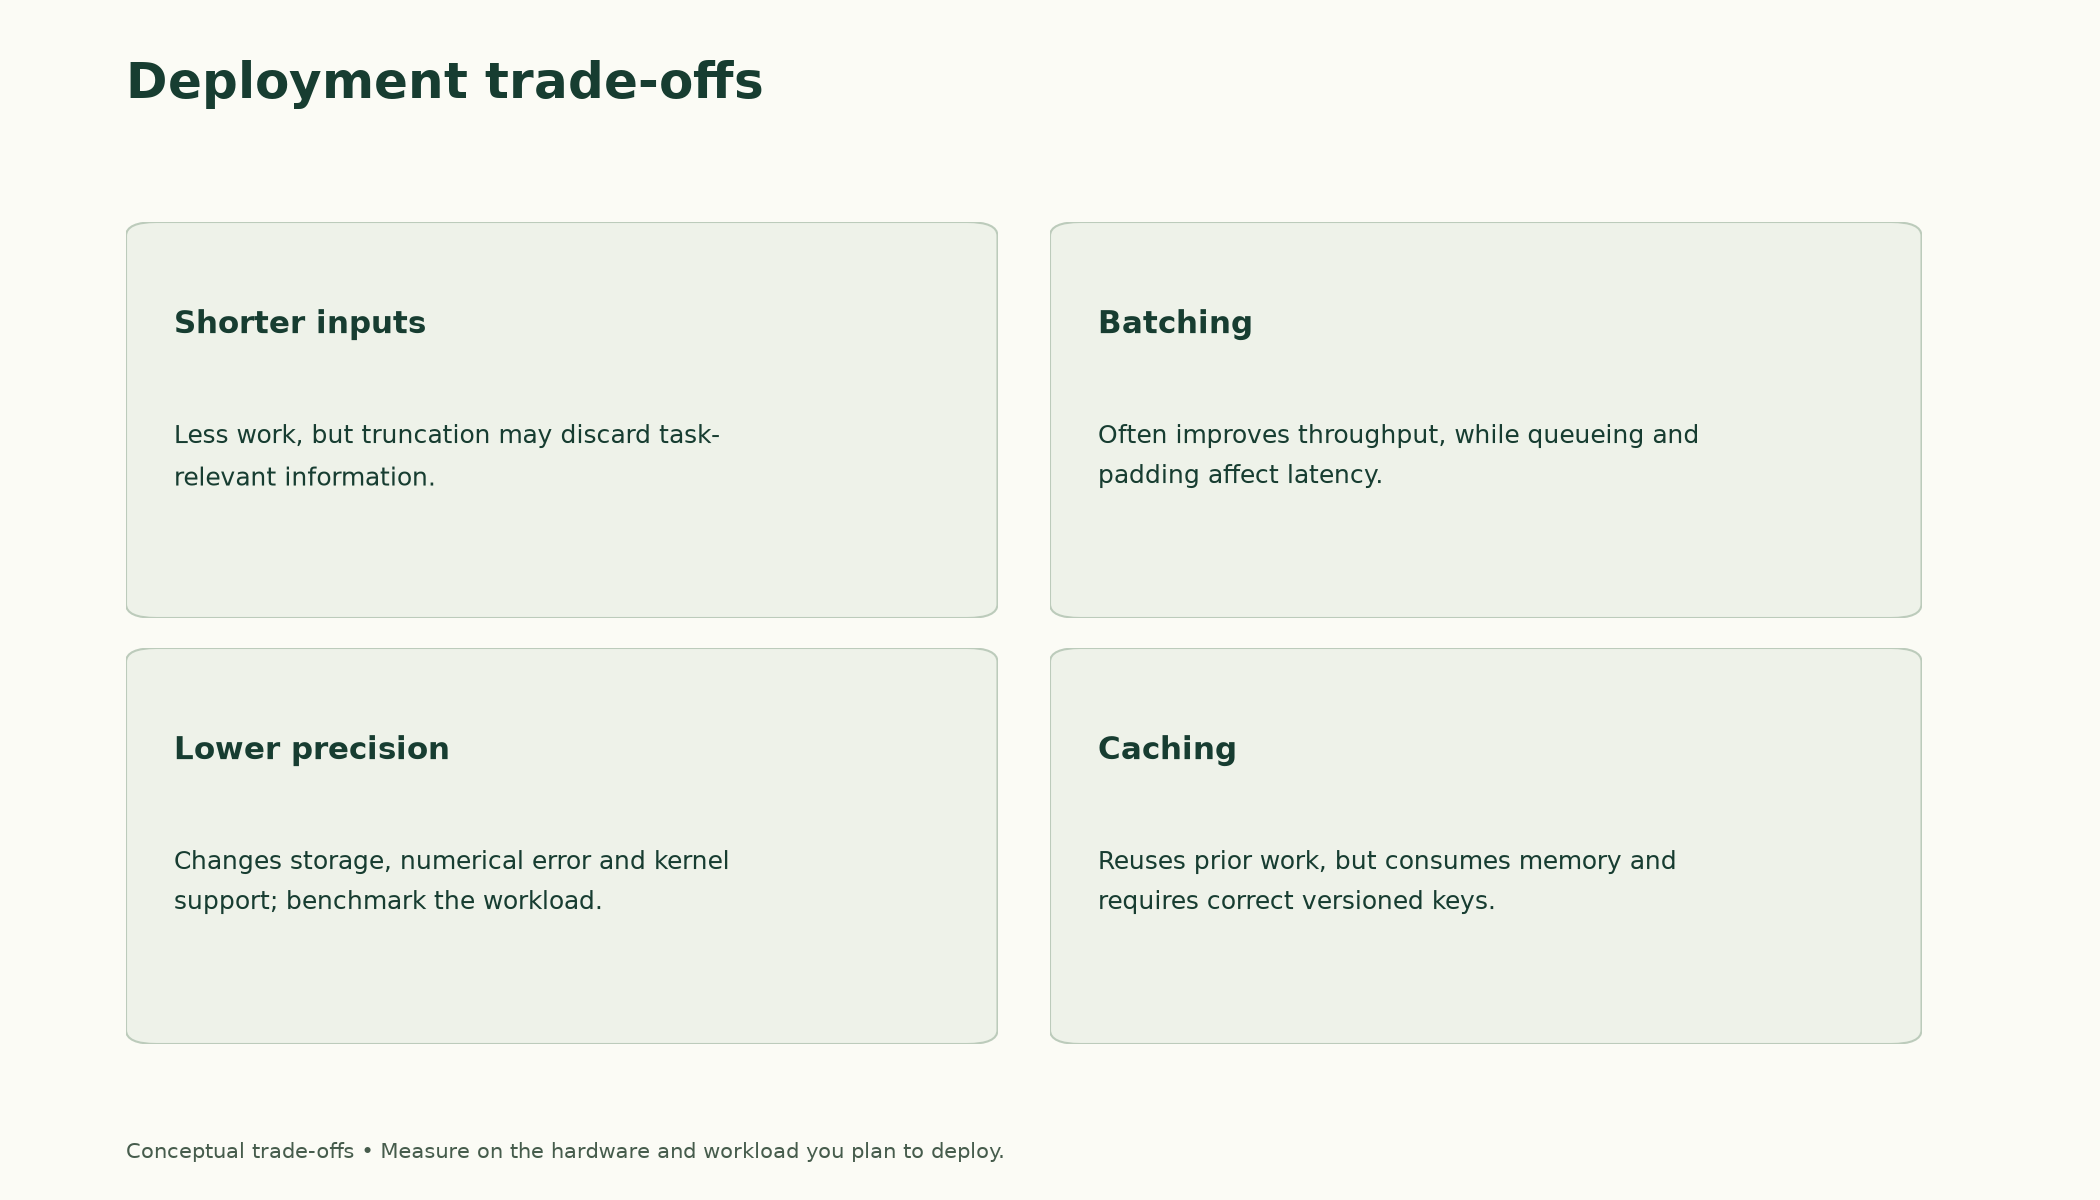

*Figure 7.6.1. Deployment choices trade quality, latency, throughput and memory. The directions shown are engineering considerations to test on the target workload, not measured universal laws.*

We'll use the fixed IMDb split from Note 7.1 (the function is copied here; the fingerprints confirm the reviews are the same).

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


## 2. Latency and Throughput

**Latency** is the time from receiving one request to returning its answer: what a single user experiences. **Throughput** is how many requests the system completes per second: what the operator pays for. They're related but not the same, and improving one can hurt the other.

We load the sentiment model explicitly, as in Note 7.4, with a small helper that runs a list of texts and returns their logits.

In [4]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))
model = AutoModelForSequenceClassification.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2)).to(device).eval()

def logits_for(m, texts, max_length=256):
    enc = tokenizer(texts, truncation=True, max_length=max_length, padding=True, return_tensors="pt").to(device)
    with torch.inference_mode():
        return m(**enc).logits.float().cpu()                         # (len(texts), 2)

W1017 14:34:59.556000 78434 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 14:34:59.662000 78434 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 14:34:59.683000 78434 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 26984.70it/s]

### 2.1 Latency is a distribution

Now we send 100 validation reviews, one request at a time, and time each one. We report the median, the 95th percentile (**p95**: 95% of requests were faster than this) and the slowest.

In [5]:
requests = imdb["val_eval"][0][:100]                                  # 100 validation reviews, one request each
logits_for(model, requests[:1])                                       # warm-up, not timed
latency, n_tokens = [], []
for r in requests:
    t0 = benchmark_clock()
    logits_for(model, [r])
    latency.append((benchmark_clock() - t0) * 1000)
    n_tokens.append(len(tokenizer(r, truncation=True, max_length=256)["input_ids"]))
latency, n_tokens = np.array(latency), np.array(n_tokens)
print(f"latency per request: median {np.median(latency):.1f} ms | 95th percentile {np.percentile(latency, 95):.1f} ms | max {latency.max():.1f} ms")
print(f"one request at a time: {1000 / latency.mean():.1f} examples/s")

latency per request: median 23.4 ms | 95th percentile 27.9 ms | max 30.8 ms
one request at a time: 44.8 examples/s


Latency is not a single number. Some requests take noticeably longer than the median, and in a real service the slow ones are what users complain about. That is why services set targets on high percentiles ("p95 under 50 ms") rather than on the average. Here the main cause of the spread is easy to see:

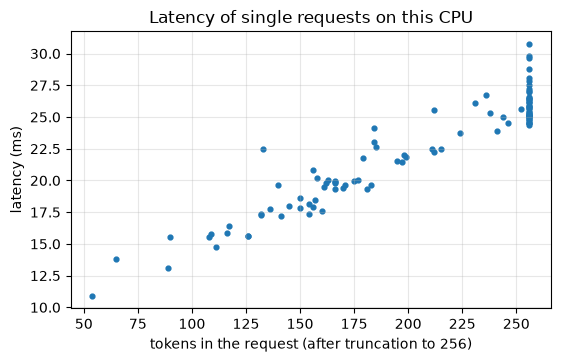

requests at the 256-token limit: 40 of 100


In [6]:
plt.figure(figsize=(6.2, 3.6))
plt.scatter(n_tokens, latency, s=12)
plt.xlabel("tokens in the request (after truncation to 256)"); plt.ylabel("latency (ms)")
plt.title("Latency of single requests on this CPU"); plt.grid(alpha=0.3); plt.show()
print(f"requests at the 256-token limit: {(n_tokens == 256).sum()} of {len(n_tokens)}")

Latency rises in a nearly straight line with the number of tokens in the request, as Note 7.3 predicted for a model of this size. The cluster on the right is the 40 of 100 reviews that hit the 256-token limit: truncation also caps the worst-case latency. Lowering `max_length` is therefore a direct latency lever, paid for in accuracy on long reviews (Note 7.3, Section 4).

### 2.2 Throughput and batching

Serving requests one at a time is simple, but it leaves the hardware under-used. If many requests arrive together, we can batch them (Note 7.4):

In [7]:
texts = imdb["val_eval"][0][:256]
order = np.argsort([len(t) for t in texts])                           # sort by length (Note 7.4)
t0 = benchmark_clock()
for i in range(0, len(texts), 32):
    logits_for(model, [texts[j] for j in order[i:i + 32]])
print(f"batches of 32, sorted by length: {len(texts) / (benchmark_clock() - t0):.1f} examples/s")

batches of 32, sorted by length: 61.2 examples/s


Batching 32 reviews at a time, sorted by length, processes more reviews per second than handling them one by one. That's the throughput side. The latency side is the catch: in a live service, a request that arrives first has to wait for the batch to fill before it is processed. Real servers use **dynamic batching**: collect whatever requests arrive within a short window (a few milliseconds), run them together, and return each result. A larger window gives bigger batches and more throughput, at the price of a little extra latency for everyone.

> **Key terms**
> - **Latency:** the time to serve one request.
> - **Throughput:** the number of requests served per second.
> - **Percentile (p95):** the value below which 95% of measurements fall; used to describe the slow end of latency.
> - **Dynamic batching:** grouping requests that arrive close together in time into one batch.

> **Common mistake:** reporting only average latency. A service whose average is fine but whose slowest 5% of requests take ten times longer will still frustrate users. Report percentiles, and look at what makes the slow requests slow.

**Check yourself.**

1. Your service must answer each request within 100 ms, and requests arrive one at a time, a few per minute. Would you use dynamic batching? Why or why not?

<details>
<summary>Worked answer</summary>

No. With requests arriving a few per minute, a batching window would almost never collect more than one request, so there's no throughput to gain, and every request would wait for the window to close, adding latency for nothing. Dynamic batching pays off when many requests arrive close together.

</details>

## 3. CPU vs. GPU Inference

A **GPU** (graphics processing unit) has thousands of simple arithmetic units that work in parallel, and a Transformer is mostly large matrix multiplications, which parallelise very well. So GPUs usually run Transformers much faster than CPUs, *if* they are given enough work at once. That last condition is why batching matters more on a GPU: a single short request leaves most of a GPU idle, while a batch of 32 or 64 keeps it busy. On a CPU, as we just measured, batching gives a smaller gain.

The cell below compares the two if your machine has an NVIDIA GPU; otherwise it says so and skips the timing.

In [8]:
print("CUDA GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    gpu_model = copy.deepcopy(model).to("cuda").eval()
    batch = tokenizer(texts[:32], truncation=True, max_length=256, padding=True, return_tensors="pt")
    for name, m, dev in [("CPU", copy.deepcopy(model).cpu(), "cpu"), ("GPU", gpu_model, "cuda")]:
        enc = {k: v.to(dev) for k, v in batch.items()}
        with torch.inference_mode():
            m(**enc); torch.cuda.synchronize()
            t0 = benchmark_clock(); m(**enc); torch.cuda.synchronize()
        print(f"{name}: {32 / (benchmark_clock() - t0):.1f} examples/s")
else:
    print("No CUDA GPU on this machine, so the CPU-vs-GPU timing is skipped.")

CUDA GPU available: False
No CUDA GPU on this machine, so the CPU-vs-GPU timing is skipped.


These notes were run on a CPU, so the comparison was skipped. If your machine has an NVIDIA GPU, you'll see both numbers, and you'll typically find the GPU many times faster on the batch. A few practical points either way:
- **A GPU has its own memory.** The model and every batch must fit in GPU memory, which is often smaller than the computer's main memory. Section 4 shows how to estimate that.
- **Moving data costs time.** Inputs travel from main memory to the GPU and results travel back, which is why `to(device)` sits around every batch, and why tiny requests gain little.
- **Cost and availability differ.** GPUs are expensive to buy or rent, and a small model like ours may serve its traffic perfectly well from cheap CPU machines. Measure before assuming you need one.
- **Other accelerators exist.** Apple computers have their own GPU, which PyTorch calls `mps`. That's why Note 7.4 asked you to pass `device=` explicitly, so the same code doesn't silently run on different hardware for different people.

> **Key terms**
> - **GPU:** a processor with many parallel arithmetic units, well suited to the matrix multiplications in neural networks.
> - **GPU memory:** the GPU's own memory, which must hold the model and each batch.

**Check yourself.**

1. A colleague benchmarks a model on a GPU with batch size 1 and concludes "the GPU is barely faster than the CPU, so it isn't worth it". What would you ask them to try?

<details>
<summary>Worked answer</summary>

Try larger batch sizes, such as 32 or 64. A single request leaves most of a GPU's parallel units idle, and the time to move data to and from the GPU dominates. With a full batch, the GPU's advantage usually shows clearly. They should also make sure they synchronise before stopping the timer, since GPU work runs in the background.

</details>

## 4. Memory Requirements and Model Size

### 4.1 Parameters × bytes, checked

Since Note 7.1 we have estimated model size as parameters × bytes per parameter. Let's check that rule against the model's actual tensors in three number formats.

In [9]:
n_params = sum(p.numel() for p in model.parameters())
def weight_bytes(m):
    return sum(t.numel() * t.element_size() for t in m.state_dict().values())
print(f"parameters: {n_params:,}")
for dtype in (torch.float32, torch.float16, torch.bfloat16):
    m = copy.deepcopy(model).to(dtype)
    bits = torch.finfo(dtype).bits
    print(f"{str(dtype):<15} {bits} bits = {bits // 8} bytes | predicted {n_params * bits // 8 / 1e6:6.1f} MB | measured {weight_bytes(m) / 1e6:6.1f} MB")

parameters: 66,955,010
torch.float32   32 bits = 4 bytes | predicted  267.8 MB | measured  267.8 MB
torch.float16   16 bits = 2 bytes | predicted  133.9 MB | measured  133.9 MB
torch.bfloat16  16 bits = 2 bytes | predicted  133.9 MB | measured  133.9 MB


The rule is exact: 66,955,010 parameters take 267.8 MB in float32 (4 bytes each) and 133.9 MB in either 16-bit format (2 bytes each). Halving the bytes halves the memory. Remember that this is the *weights only*: running the model also needs memory for activations, which grows with batch size and length (Note 7.4, Section 6), and generation adds the KV cache (Section 6 below).

### 4.2 What fewer bits cost

Fewer bits means each number is stored less exactly, or within a smaller range. The two 16-bit formats make different trade-offs:

In [10]:
for dtype in (torch.float32, torch.float16, torch.bfloat16):
    fi = torch.finfo(dtype)
    print(f"{str(dtype):<15} largest {fi.max:9.3g} | smallest normal {fi.tiny:9.3g} | relative precision {fi.eps:.1e}")
for dtype in (torch.float32, torch.float16, torch.bfloat16):
    small_step = (torch.tensor(1.0, dtype=dtype) + torch.tensor(0.001, dtype=dtype)).item()   # precision
    big = torch.tensor(70000.0, dtype=dtype).item()                                            # range
    print(f"{str(dtype):<15} 1 + 0.001 = {small_step:.6f} | 70000 is stored as {big}")

torch.float32   largest   3.4e+38 | smallest normal  1.18e-38 | relative precision 1.2e-07
torch.float16   largest  6.55e+04 | smallest normal   6.1e-05 | relative precision 9.8e-04
torch.bfloat16  largest  3.39e+38 | smallest normal  1.18e-38 | relative precision 7.8e-03
torch.float32   1 + 0.001 = 1.001000 | 70000 is stored as 70000.0
torch.float16   1 + 0.001 = 1.000977 | 70000 is stored as inf
torch.bfloat16  1 + 0.001 = 1.000000 | 70000 is stored as 70144.0


The first three lines show each format's limits:
- **float32** can represent numbers up to about 3.4e+38 with a relative precision of about 1.2e-07, roughly seven significant digits.
- **float16** keeps reasonable precision (9.8e-04, about three digits) but its range stops at 6.55e+04. A larger number becomes `inf`, infinity: 70000 is stored as `inf`.
- **bfloat16** keeps float32's full range (70000 is stored as 70144.0, slightly off but not infinite) but has less precision (7.8e-03, about two digits): adding 0.001 to 1 changes nothing, giving 1.000000.

For neural networks, range is often the bigger danger, since an overflow to infinity breaks a computation completely. So bfloat16 has become the common choice for training and running large models on hardware that supports it, such as the Qwen models in Note 7.3, which are stored in BF16. Weights themselves cope well with reduced precision, which is what makes the next section possible.

> **Key terms**
> - **float32, float16, bfloat16:** 32- and 16-bit floating-point formats; bfloat16 keeps float32's range with less precision, while float16 keeps more precision with a much smaller range.
> - **Precision (relative precision):** the smallest relative difference a format can represent between two nearby numbers.
> - **Range:** the largest (and smallest) magnitudes a format can store before overflowing to infinity.
> - **Overflow:** a value too large for the format, stored as infinity.

**Check yourself.**

1. A model has 1.5 billion parameters. Estimate its weight memory in float32 and in bfloat16. Would you expect it to fit in a GPU with 4 GB of memory?

<details>
<summary>Worked answer</summary>

1.5 billion × 4 bytes = 6 GB in float32, and × 2 bytes = 3 GB in bfloat16. In bfloat16 the weights alone would take most of a 4 GB GPU, leaving little room for activations (and a KV cache, for generation), so it would be very tight. Int8 quantisation (about 1.5 GB of weights) would make it fit comfortably.

</details>

## 5. Quantisation: The Core Idea

### 5.1 Rounding weights to whole numbers

16-bit formats halve memory. **Quantisation** goes further by storing weights as small *integers*, usually 8-bit integers (**int8**), whole numbers from −127 to 127, which take 1 byte each. The trick is a **scale**: we choose a number s so that the largest weight maps to 127, divide every weight by s, round to the nearest whole number, and store the integers plus s. To use the weights, multiply back by s.

Here it is on four example weights:

In [11]:
w = torch.tensor([0.8, -0.3, 0.05, -1.27])                            # four example weights
scale = w.abs().max() / 127                                           # map the largest magnitude to 127
q = torch.round(w / scale).to(torch.int8)                             # whole numbers from -127 to 127
print("weights:     ", w.tolist())
print("scale:       ", round(scale.item(), 4))
print("int8 values: ", q.tolist())
print("dequantised: ", [round(v, 4) for v in (q.float() * scale).tolist()])

weights:      [0.800000011920929, -0.30000001192092896, 0.05000000074505806, -1.2699999809265137]
scale:        0.01
int8 values:  [80, -30, 5, -127]
dequantised:  [0.8, -0.3, 0.05, -1.27]


The largest magnitude is 1.27, so the scale is 1.27 / 127 = 0.01. Dividing by it gives 80, −30, 5 and −127, all whole numbers that fit in one byte, and multiplying back gives exactly the original weights. (The long decimals in the first line are float32's own rounding of 0.8, 0.3 and so on, from Section 4.2.) Real weights won't divide so neatly, so rounding loses a little. Let's do the same to a real layer, the first feed-forward layer of DistilBERT's first Transformer block, with one scale per output row (**per-channel** scales), since rows can have very different ranges:

In [12]:
W = model.distilbert.transformer.layer[0].ffn.lin1.weight.detach().cpu()   # (3072, 768): one feed-forward layer
scale = W.abs().amax(dim=1, keepdim=True) / 127                             # (3072, 1): one scale per output row
Wq = torch.round(W / scale).clamp(-127, 127).to(torch.int8)                 # (3072, 768) int8
W_back = Wq.float() * scale                                                 # what the int8 copy gives back
err = (W - W_back).abs()
print(f"weight shape {tuple(W.shape)} | typical weight size {W.abs().mean():.2e}")
print(f"rounding error: mean {err.mean():.2e} | largest {err.max():.2e} ({(err.mean() / W.abs().mean()):.2%} of a typical weight)")
print(f"storage: float32 {W.numel() * 4 / 1e6:.2f} MB -> int8 {Wq.numel() / 1e6:.2f} MB + scales {scale.numel() * 4 / 1e3:.1f} kB")

weight shape (3072, 768) | typical weight size 3.28e-02
rounding error: mean 2.84e-04 | largest 1.37e-03 (0.87% of a typical weight)
storage: float32 9.44 MB -> int8 2.36 MB + scales 12.3 kB


The layer's 3072 × 768 weights shrink from 9.44 MB to 2.36 MB, plus 12.3 kB of scales. The price is rounding error: on average 2.84e-04, which is 0.87% of a typical weight's size. That's small, but errors in thousands of weights add up through six layers, so the real test is the model's output.

### 5.2 The whole model

The function below applies the same rounding to every `nn.Linear` layer in a copy of the model: the attention projections, the feed-forward layers and the classifier. To keep the code simple, it puts the rounded-and-rescaled values back as float32 (so the model runs as before), and it counts what int8 storage would take.

In [13]:
def quantize_linear_weights(m):
    """Round every nn.Linear weight to int8 (one scale per row) and put the dequantised values back."""
    m = copy.deepcopy(m)
    int8_bytes = 0
    for mod in m.modules():
        if isinstance(mod, torch.nn.Linear):
            W = mod.weight.data
            s = W.abs().amax(dim=1, keepdim=True) / 127
            mod.weight.data = torch.round(W / s).clamp(-127, 127) * s            # simulate int8 storage
            int8_bytes += W.numel() * 1 + s.numel() * 4                         # int8 weights + float32 scales
    linear_w = sum(mod.weight.numel() for mod in m.modules() if isinstance(mod, torch.nn.Linear))
    other_bytes = (n_params - linear_w) * 4                                   # everything else stays float32
    return m, int8_bytes + other_bytes

manual_model, manual_bytes = quantize_linear_weights(model)
emb = model.distilbert.embeddings.word_embeddings.weight.numel() + model.distilbert.embeddings.position_embeddings.weight.numel()
print(f"weights after int8 rounding of the Linear layers: {manual_bytes / 1e6:.1f} MB (float32: {n_params * 4 / 1e6:.1f} MB)")
print(f"embedding tables, still float32: {emb:,} numbers = {emb * 4 / 1e6:.1f} MB")

weights after int8 rounding of the Linear layers: 138.8 MB (float32: 267.8 MB)
embedding tables, still float32: 23,834,112 numbers = 95.3 MB


Rounding the Linear layers to int8 takes the model from 267.8 MB to 138.8 MB, about half, not a quarter. The reason is in the second line: the embedding tables (23,834,112 numbers, 95.3 MB) aren't Linear layers and stay in float32. This is Note 7.1's observation that a third of DistilBERT is embeddings, showing up again in practice.

Size is only good news if the answers survive. We compare the int8 model with the original on the first 300 validation reviews:

In [14]:
eval_x, eval_y = imdb["val_eval"][0][:300], imdb["val_eval"][1][:300]  # the first 300 validation reviews
def p_positive(m, texts):
    order = np.argsort([len(t) for t in texts])
    p = np.empty(len(texts))
    for i in range(0, len(texts), 32):
        idx = order[i:i + 32]
        p[idx] = logits_for(m, [texts[j] for j in idx]).softmax(-1)[:, 1].numpy()
    return p

p32 = p_positive(model, eval_x)
p8 = p_positive(manual_model, eval_x)
print(f"float32:          accuracy {((p32 > 0.5) == eval_y).mean():.3f}")
print(f"int8 (by hand):   accuracy {((p8 > 0.5) == eval_y).mean():.3f} | same label as float32: {((p8 > 0.5) == (p32 > 0.5)).mean():.3f} | largest probability change {np.abs(p8 - p32).max():.4f}")

float32:          accuracy 0.873
int8 (by hand):   accuracy 0.877 | same label as float32: 0.997 | largest probability change 0.0804


The original scores 0.873 on these 300 reviews, and the int8 version 0.877. They agree on 0.997 of the labels, which is all but one review, and no probability moved by more than 0.0804. With 300 reviews, one review is worth about a third of a percentage point, so the tiny accuracy difference is one review changing sides, not a real improvement. Quantisation cost us essentially nothing here.

### 5.3 The library route

In practice you don't write quantisation by hand. **torchao**, PyTorch's quantisation library, does the same int8 weight-only quantisation in one line, replacing each Linear layer's weights with real int8 tensors:

In [15]:
from torchao.quantization import quantize_, Int8WeightOnlyConfig
ao_model = copy.deepcopy(model)
quantize_(ao_model, Int8WeightOnlyConfig())                           # replaces Linear weights with int8 tensors
buf = io.BytesIO(); torch.save(ao_model.state_dict(), buf)
print(f"torchao int8 weights saved: {buf.tell() / 1e6:.1f} MB")
p_ao = p_positive(ao_model, eval_x)
print(f"int8 (torchao):   accuracy {((p_ao > 0.5) == eval_y).mean():.3f} | same label as float32: {((p_ao > 0.5) == (p32 > 0.5)).mean():.3f} | largest probability change {np.abs(p_ao - p32).max():.4f}")

torchao int8 weights saved: 138.9 MB


int8 (torchao):   accuracy 0.877 | same label as float32: 0.997 | largest probability change 0.0886


torchao's model saves to 138.9 MB, matching our hand-built estimate, with the same accuracy (0.877) and the same agreement (0.997) with the original. Our by-hand version *was* the core idea; the library adds efficient storage and computation.

### 5.4 Smaller is not automatically faster

Does a smaller model run faster? Let's time the original, a bfloat16 copy and the torchao int8 model on the same 16 reviews:

In [16]:
sample = imdb["val_eval"][0][:16]
bf16_model = copy.deepcopy(model).to(torch.bfloat16)
for name, m in [("float32", model), ("bfloat16", bf16_model), ("int8 (torchao)", ao_model)]:
    logits_for(m, sample[:2])                                          # warm-up
    t0 = benchmark_clock()
    logits_for(m, sample)
    print(f"{name:<15} {(benchmark_clock() - t0) / len(sample) * 1000:7.1f} ms per review")
del bf16_model, manual_model

float32            19.6 ms per review


bfloat16          159.0 ms per review


int8 (torchao)     20.5 ms per review


On this CPU, neither smaller version is faster. The bfloat16 copy is several times *slower* than float32, and the int8 model is somewhat slower too. Speed depends on whether the hardware and software have fast routines (**kernels**) for the number format. This processor and this PyTorch build are heavily optimised for float32 matrix multiplication. Many GPUs and some server CPUs have dedicated fast paths for 16-bit and int8 arithmetic, and there these formats are typically faster as well as smaller. So the reliable benefit of quantisation is memory, while the speed benefit depends on the hardware. Measure on the machine you will deploy to.

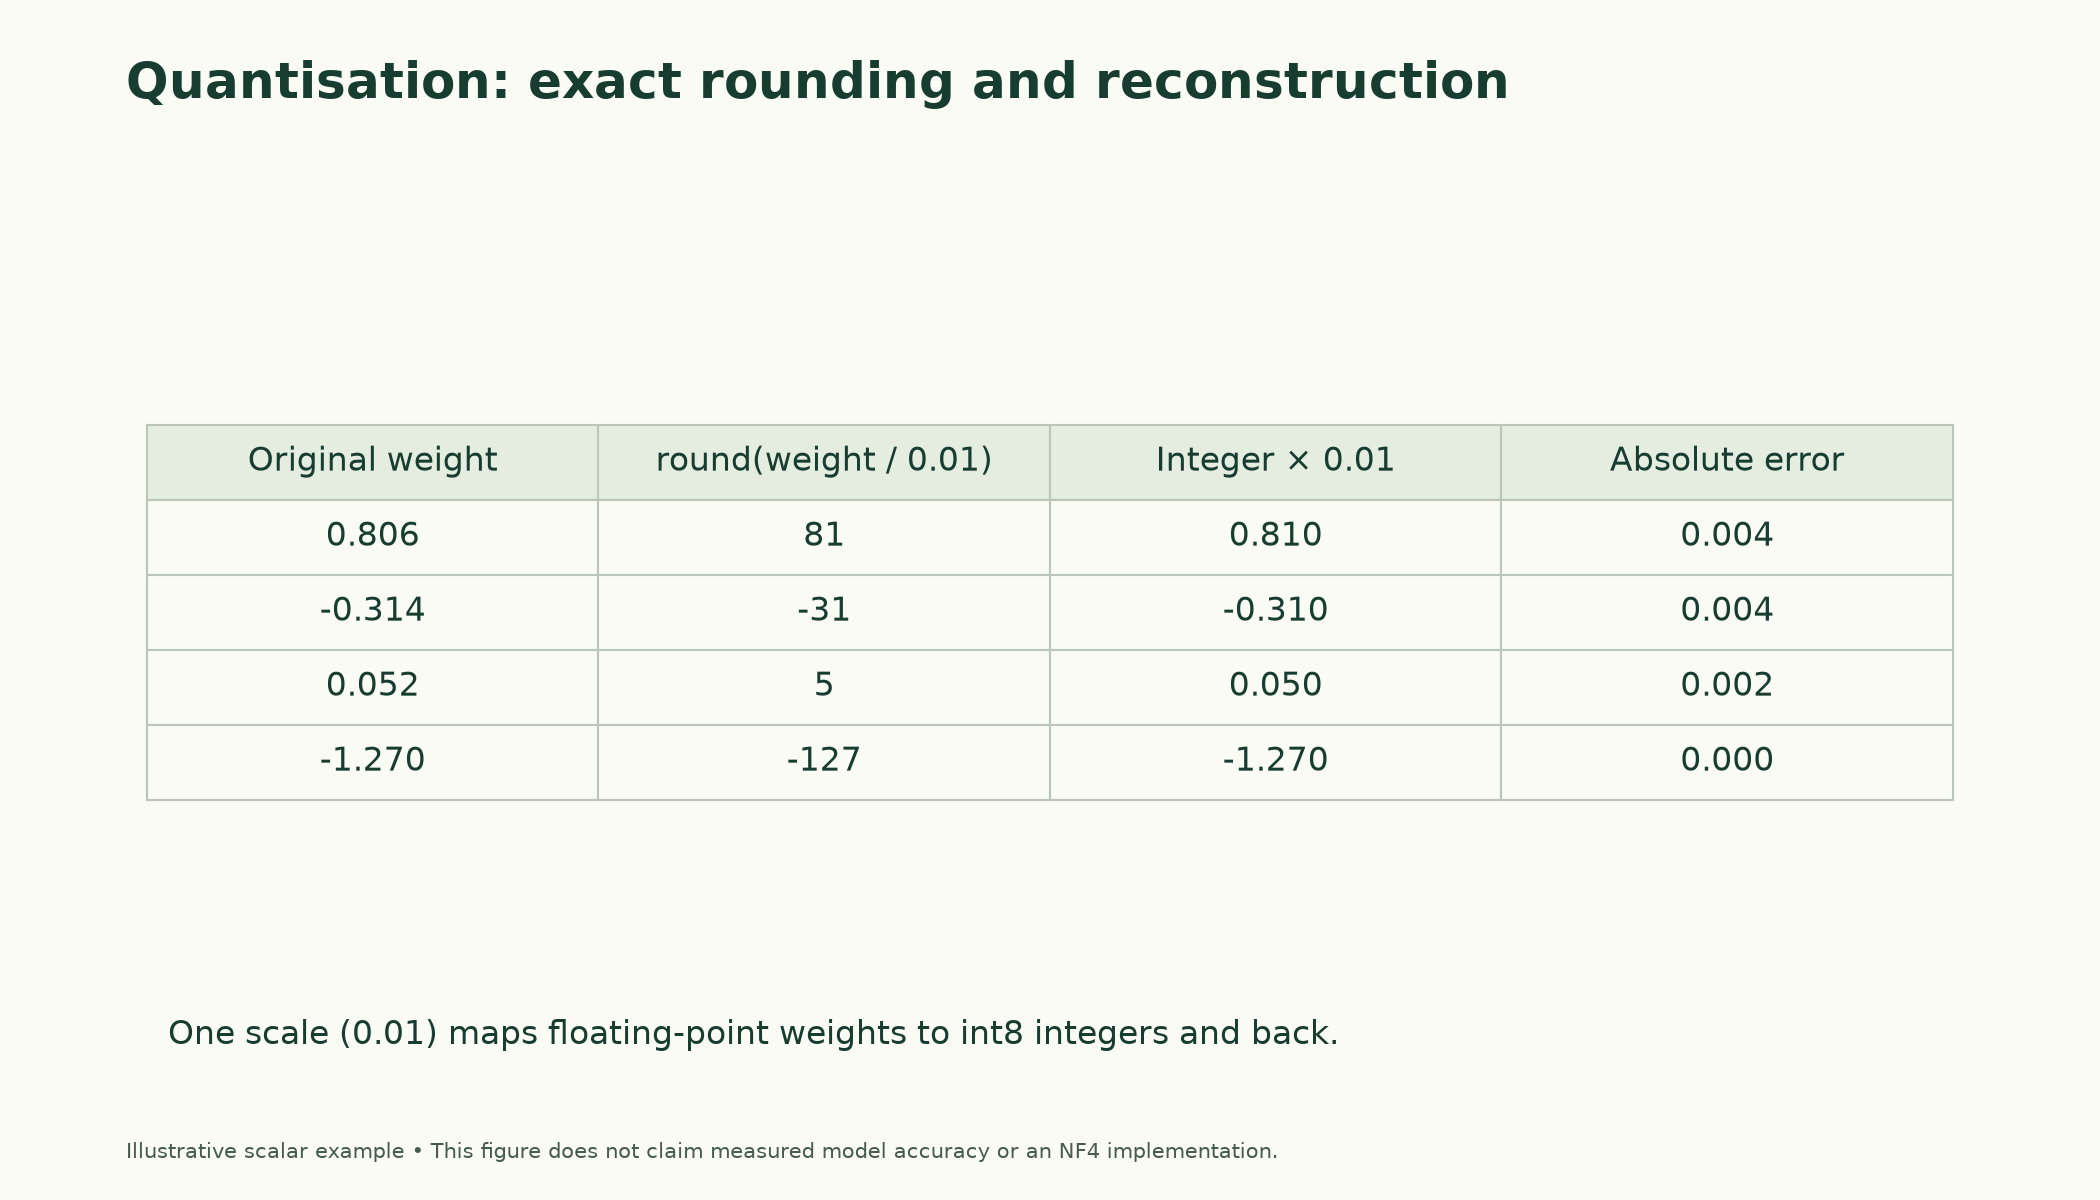

*Figure 7.6.2. Illustrative symmetric rounding with scale 0.01. The exact reconstruction arithmetic is computed in the figure script; it is separate from the notebook's measured model experiment.*

> **Key terms**
> - **Quantisation:** storing numbers with fewer bits, here as 8-bit integers plus a scale.
> - **int8:** 8-bit integers, 1 byte each; we use −127 to 127.
> - **Scale:** the number that converts between the original values and the integers.
> - **Per-channel quantisation:** using a separate scale for each row (output channel) of a weight matrix.
> - **Weight-only quantisation:** quantising the stored weights while computing with higher-precision activations.
> - **Kernel:** a low-level routine that performs an operation, such as matrix multiplication, for a particular hardware and number format.

> **Common mistake:** assuming quantisation always makes a model faster. It always reduces memory, but speed depends on whether your hardware has fast int8 or 16-bit kernels. On this CPU, both smaller formats were slower than float32.

**Check yourself.**

1. Why did int8 quantisation of the Linear layers bring DistilBERT only from 267.8 MB to 138.8 MB, rather than to a quarter of its size? What would you have to quantise to get closer to a quarter?

<details>
<summary>Worked answer</summary>

Because only the Linear layers were quantised. The embedding tables, 95.3 MB of the original 267.8 MB, stayed in float32 at 4 bytes per number. To get closer to a quarter, you would also have to quantise the embeddings (and any other large float32 tensors); libraries offer this, with the usual need to check accuracy afterwards.

</details>

**Visual walkthrough: Round, reconstruct, measure error.**

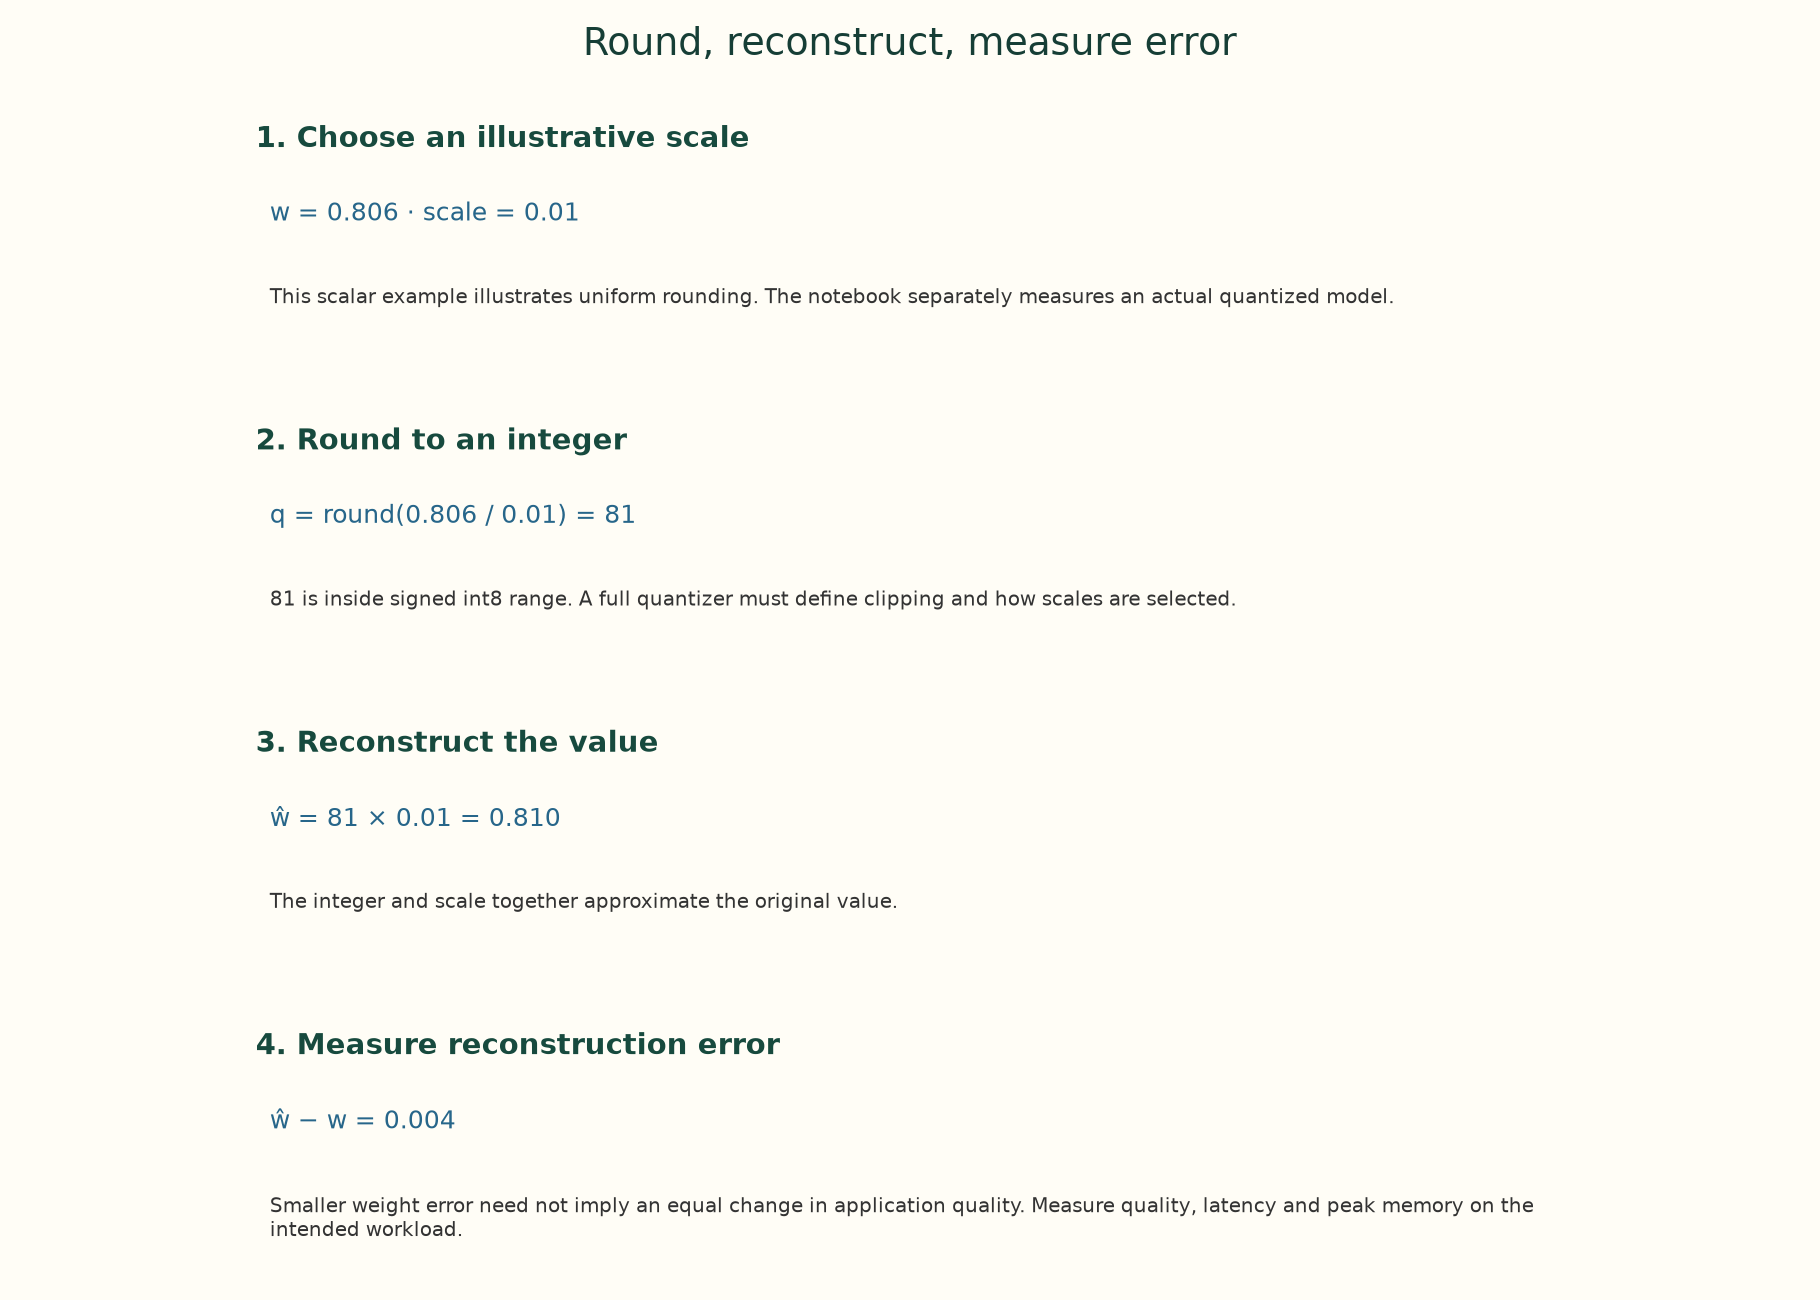

**1. Choose an illustrative scale.** w = 0.806 · scale = 0.01. This scalar example illustrates uniform rounding. The notebook separately measures an actual quantized model.

**2. Round to an integer.** q = round(0.806 / 0.01) = 81. 81 is inside signed int8 range. A full quantizer must define clipping and how scales are selected.

**3. Reconstruct the value.** ŵ = 81 × 0.01 = 0.810. The integer and scale together approximate the original value.

**4. Measure reconstruction error.** ŵ − w = 0.004. Smaller weight error need not imply an equal change in application quality. Measure quality, latency and peak memory on the intended workload.

*The app adds a paused animation of this same supplied example.*

## 6. Batching, Caching and Resource Utilisation

The cheapest computation is the one you don't do. Sections 2 and 3 covered batching, which does the same work more efficiently. This section covers two kinds of **caching**, which avoid repeating work at all.

### 6.1 Caching responses

In many applications the same inputs come up again and again: popular products, common questions, a viral review. A **response cache** stores each answer the first time it is computed and returns it directly for later identical requests. We simulate 1,000 requests drawn from 200 reviews, where, as in real traffic, a few reviews are requested far more often than others:

In [17]:
rng = np.random.default_rng(0)
catalogue = imdb["val_eval"][0][:200]                                 # 200 reviews that users ask about
popularity = 1 / np.arange(1, 201); popularity /= popularity.sum()   # a few are requested far more often
stream = rng.choice(200, size=1000, p=popularity)                     # 1,000 requests
cache, model_calls = {}, 0
for i in stream:
    key = (SST2, 256, catalogue[i])                                   # model, settings and input
    if key not in cache:
        model_calls += 1
        cache[key] = None                                             # (the prediction would be stored here)
print(f"requests: {len(stream)} | distinct reviews requested: {len(set(stream))} | model calls with a cache: {model_calls} | hit rate {1 - model_calls / len(stream):.1%}")

requests: 1000 | distinct reviews requested: 163 | model calls with a cache: 163 | hit rate 83.7%


Only 163 distinct reviews were requested among the 1,000 requests, so with a cache the model runs 163 times and the other 83.7% of requests are answered instantly from memory. How well a cache works depends entirely on how repetitive your traffic is, so measure that on real request logs before building one.

Notice the **cache key**: it contains the model name and the `max_length` setting as well as the text. If you update the model or change a setting, old cached answers must not be served as if they came from the new configuration. Forgetting this is a classic source of confusing bugs.

### 6.2 The KV cache in text generation

Generation has its own, internal cache. In Note 6.6 we saw that a decoder generates one token at a time, and that each new token attends to all the previous ones. Without a cache, every step reruns the model over the *whole* text so far, recomputing keys and values for tokens that haven't changed. The **KV cache** stores each token's keys and values once and reuses them, so each step only processes the one new token. Let's time distilgpt2 generating 100 tokens both ways:

In [18]:
GPT = "distilbert/distilgpt2"
gen_tok = AutoTokenizer.from_pretrained(GPT, revision=MODEL_REVISIONS.get(GPT))
gen_model = AutoModelForCausalLM.from_pretrained(GPT, revision=MODEL_REVISIONS.get(GPT)).to(device).eval()
enc = gen_tok("The film opens with a long, quiet shot of", return_tensors="pt").to(device)
outputs = {}
for use_cache in (True, False):
    with torch.inference_mode():
        gen_model.generate(**enc, max_new_tokens=5, do_sample=False, use_cache=use_cache, pad_token_id=gen_tok.eos_token_id)
        t0 = benchmark_clock()
        outputs[use_cache] = gen_model.generate(**enc, max_new_tokens=100, do_sample=False, use_cache=use_cache,
                                                pad_token_id=gen_tok.eos_token_id)
    print(f"use_cache={use_cache!s:<5}: {(benchmark_clock() - t0) * 1000:.0f} ms for 100 new tokens")
print("identical text with and without the cache:", torch.equal(outputs[True], outputs[False]))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 9320.40it/s]

use_cache=True : 379 ms for 100 new tokens


use_cache=False: 1300 ms for 100 new tokens
identical text with and without the cache: True


With the cache, generation is several times faster, and the text is identical: the cache changes how much work is done, not the result. Counting the token positions the model processes shows why:

In [19]:
prompt_len, new = enc["input_ids"].shape[1], 100
without = sum(prompt_len + t for t in range(new))                     # every step re-reads the whole text so far
with_cache = prompt_len + (new - 1)                                    # the prompt once, then one new token per step
print(f"prompt: {prompt_len} tokens | positions processed for 100 new tokens: without cache {without:,} | with cache {with_cache:,}")
del gen_model

prompt: 10 tokens | positions processed for 100 new tokens: without cache 5,950 | with cache 109


For a 10-token prompt and 100 new tokens, generating without the cache processes 5,950 token positions, because every step re-reads everything before it. With the cache it processes 109: the prompt once, then one new position per step. The timing gap was smaller than this count suggests, because each cached step also has to attend over all the stored keys and values, and each step has fixed overheads. The longer the text, the bigger the saving. The KV cache does cost memory, though: it holds keys and values for every layer and every past token, and for long conversations with large models it can rival the weights themselves in size.

### 6.3 Resource utilisation

Put together, a well-run inference service keeps the hardware busy with useful work. It **batches** requests so the processor is fully used, **sorts or buckets** by length so little of that work is padding (Note 7.4), **caches** repeated responses, uses the **KV cache** for generation, and **sizes** the model and its number format to the machine's memory. Each lever trades something away (batching adds waiting time, caching uses memory and risks stale answers, quantisation may cost accuracy), so the right mix depends on your traffic and your latency target.

> **Key terms**
> - **Response cache:** stored answers to previous requests, returned directly when the same request repeats.
> - **Cache key:** the information that identifies a cached answer; it must include everything that affects the answer (input, model version, settings).
> - **Cache hit rate:** the share of requests answered from the cache.
> - **KV cache:** stored attention keys and values for past tokens, reused at each generation step.

**Check yourself.**

1. You upgrade your service to a newer model but forget to change the cache key, which contains only the input text. What will users experience, and for how long?

<details>
<summary>Worked answer</summary>

Users will receive the *old* model's answers for every input that was cached before the upgrade, while new inputs get the new model's answers. The service will behave as a confusing mix of two models, until each cached entry expires or the cache is cleared, which may be never if the cache has no expiry. The fix is to include the model version in the key, so a new model starts with a fresh cache.

</details>

## 7. Hosted vs. Local Inference

Note 7.3 compared hosted APIs and local models in general terms. With the measurements from this note, we can be more concrete about what "running it yourself" involves.

Running locally means **you own every constraint in this note**: you measure latency and throughput, choose the hardware (CPU or GPU) and the number format, decide batching and caching, size the machines for peak traffic, and keep them running. In return you get control: the exact model version, data that never leaves your systems, and costs that are mostly fixed regardless of how many requests you serve.

Using a hosted service means **the provider owns most of them**: they choose hardware, batching and quantisation, and you pay per request or per token. You give up control over versions and data location, and you add a network round trip to every request's latency.

| | Local (self-hosted) | Hosted API |
|---|---|---|
| Latency | Model time only; you control it | Model time plus network round trip |
| Throughput | Limited by the machines you run | Scales with the provider, within rate limits |
| Memory and hardware | Your problem: size the model to the machine | The provider's problem |
| Cost | Mostly fixed (machines), cheaper at high steady volume | Grows with use, cheaper at low or bursty volume |
| Versions | Pinned by you (Section 8) | The provider may change or retire a model |
| Data | Stays on your systems | Sent to the provider |

A useful way to decide is a **break-even** estimate: work out what a hosted service would charge for your expected monthly requests, and compare it with the monthly cost of machines that can serve the same traffic, using throughput measured as in Section 2. Below the break-even volume, hosted is usually cheaper and simpler; above it, local usually wins, if you have the skills to run it.

> **Key terms**
> - **Self-hosting:** running a model on machines you control.
> - **Break-even volume:** the request volume at which self-hosting and a hosted service cost the same.

**Check yourself.**

1. A startup expects a few hundred requests a day at first, possibly growing a hundredfold within a year. Which option would you suggest at launch, and what would you measure to decide whether to switch later?

<details>
<summary>Worked answer</summary>

At launch, a hosted service: a few hundred requests a day cost little, and you avoid running machines. Measure the monthly request volume and its growth, the hosted cost per request, and the throughput a local machine achieves for your model, as in Section 2. When the projected hosted bill exceeds the cost of machines that could serve the traffic (plus the effort of running them), it's time to consider self-hosting. Privacy or version-control needs may also force the switch earlier.

</details>

## 8. Model Versioning and Reproducibility

A deployed model must give the same answer to the same input, both from one request to the next and from one month to the next, unless you decide to change it. Three things make that possible.

**Record exactly what you ran.** A short **manifest** written next to your results lists the model and its exact commit, the settings, the evaluation data's fingerprint, the result, and the software versions:

In [20]:
info = HfApi().model_info(SST2, revision=MODEL_REVISIONS.get(SST2))
manifest = {
    "model": SST2,
    "revision": info.sha,                                             # the exact commit of the weights
    "max_length": 256,
    "eval_set": "IMDb val_eval, first 300 reviews",
    "eval_fingerprint": fingerprint(eval_x),
    "accuracy": round(float(((p32 > 0.5) == eval_y).mean()), 4),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
}
print(json.dumps(manifest, indent=2))

{
  "model": "distilbert/distilbert-base-uncased-finetuned-sst-2-english",
  "revision": "714eb0fa89d2f80546fda750413ed43d93601a13",
  "max_length": 256,
  "eval_set": "IMDb val_eval, first 300 reviews",
  "eval_fingerprint": "52b8a6ed1ef8",
  "accuracy": 0.8733,
  "python": "3.12.15",
  "torch": "2.14.1",
  "transformers": "5.20.1"
}


Everything needed to reproduce the 0.8733 accuracy is here: the repository and the commit `714eb0fa…` (Note 7.1, Section 7), `max_length` 256, which reviews were used (with a fingerprint, `52b8a6ed1ef8`, to check they're the same), and the Python, PyTorch and Transformers versions. Saved as a JSON file next to a deployed model, a manifest like this answers "which model produced this?" months later.

**Check that inference is deterministic.** In eval mode, the same input should give exactly the same output (Note 7.4):

In [21]:
a = logits_for(model, [eval_x[0]])
b = logits_for(model, [eval_x[0]])
batched = logits_for(model, eval_x[:8])[0:1]                          # the same review inside a padded batch of 8
print("same input twice, identical logits:", torch.equal(a, b))
print(f"alone vs. inside a batch: largest logit difference {(a - batched).abs().max().item():.2e}")

same input twice, identical logits: True
alone vs. inside a batch: largest logit difference 1.91e-06


The same review gives bit-identical logits twice in a row. Processed inside a padded batch of 8, its logits differ by at most 1.91e-06, the tiny floating-point differences that come from doing arithmetic in a different order. That level is harmless for a label, but it means "identical" comparisons in tests should use a tolerance, and it explains why a score can wobble in its last digits between a batched and an unbatched service.

**Pin the software too.** Library updates can change tokenisation, defaults or numerical details. A `requirements.txt` with exact versions, like the one that comes with these notes, together with the pinned model commit, is what makes a result reproducible by someone else.

> **Key terms**
> - **Manifest:** a small file recording the model, its exact version, settings, evaluation data and software versions behind a result.
> - **Deterministic inference:** getting exactly the same output for the same input every time.
> - **Tolerance:** the small difference allowed when comparing floating-point results.

> **Common mistake:** recording only the model's *name*. A name like `distilbert-base-uncased-finetuned-sst-2-english` can point to different weights over time; the commit ID, the settings and the library versions are what pin a result down.

## Putting It All Together

Let's reassemble the deployment picture.

A model becomes a feature only when it meets its **constraints**. **Latency** is a distribution, not a number. For our model it rose in a straight line with request length, and truncation capped the slow end; services set targets on percentiles such as p95. **Throughput** rises with batching, at the cost of waiting time; on a **GPU**, batching matters even more. **Memory** follows parameters × bytes exactly: 267.8 MB in float32, 133.9 MB in float16 or bfloat16, where bfloat16 keeps the range (70000 stays finite) and float16 keeps the precision.

**Quantisation** stores weights as int8 plus a scale. By hand and with torchao, it took DistilBERT to 138.8–138.9 MB, not a quarter, because the 95.3 MB of embeddings stayed float32, and the answers agreed with float32 on 0.997 of 300 reviews. On this CPU neither 16-bit nor int8 was faster: memory savings are reliable, while speed depends on the hardware's kernels. **Caching** avoids work entirely: a response cache answered 83.7% of a skewed request stream without the model, and the KV cache cut generation from 5,950 processed positions to 109, with identical text.

**Hosted or local** decides who owns these constraints, and a break-even estimate built on measured throughput decides which is cheaper. **Reproducibility** comes from a manifest (model commit, settings, data fingerprint, versions), deterministic eval-mode inference, and pinned software.

| Lever | What it buys | What it costs | Measured here |
|---|---|---|---|
| Shorter `max_length` | lower latency | accuracy on long inputs | latency rose in step with tokens |
| Batching | throughput | waiting time per request | more examples/s in batches of 32 |
| bfloat16 / float16 | half the memory | precision or range; speed depends on hardware | 133.9 MB; slower on this CPU |
| int8 quantisation | about half the memory here | small accuracy risk; speed depends on hardware | 138.9 MB; 0.997 agreement |
| Response cache | skipped model calls | memory; stale answers if the key is wrong | 83.7% hit rate |
| KV cache | faster generation | memory per token | 5,950 → 109 positions |
| Manifest + pins | reproducibility | discipline | commit, fingerprint, versions |

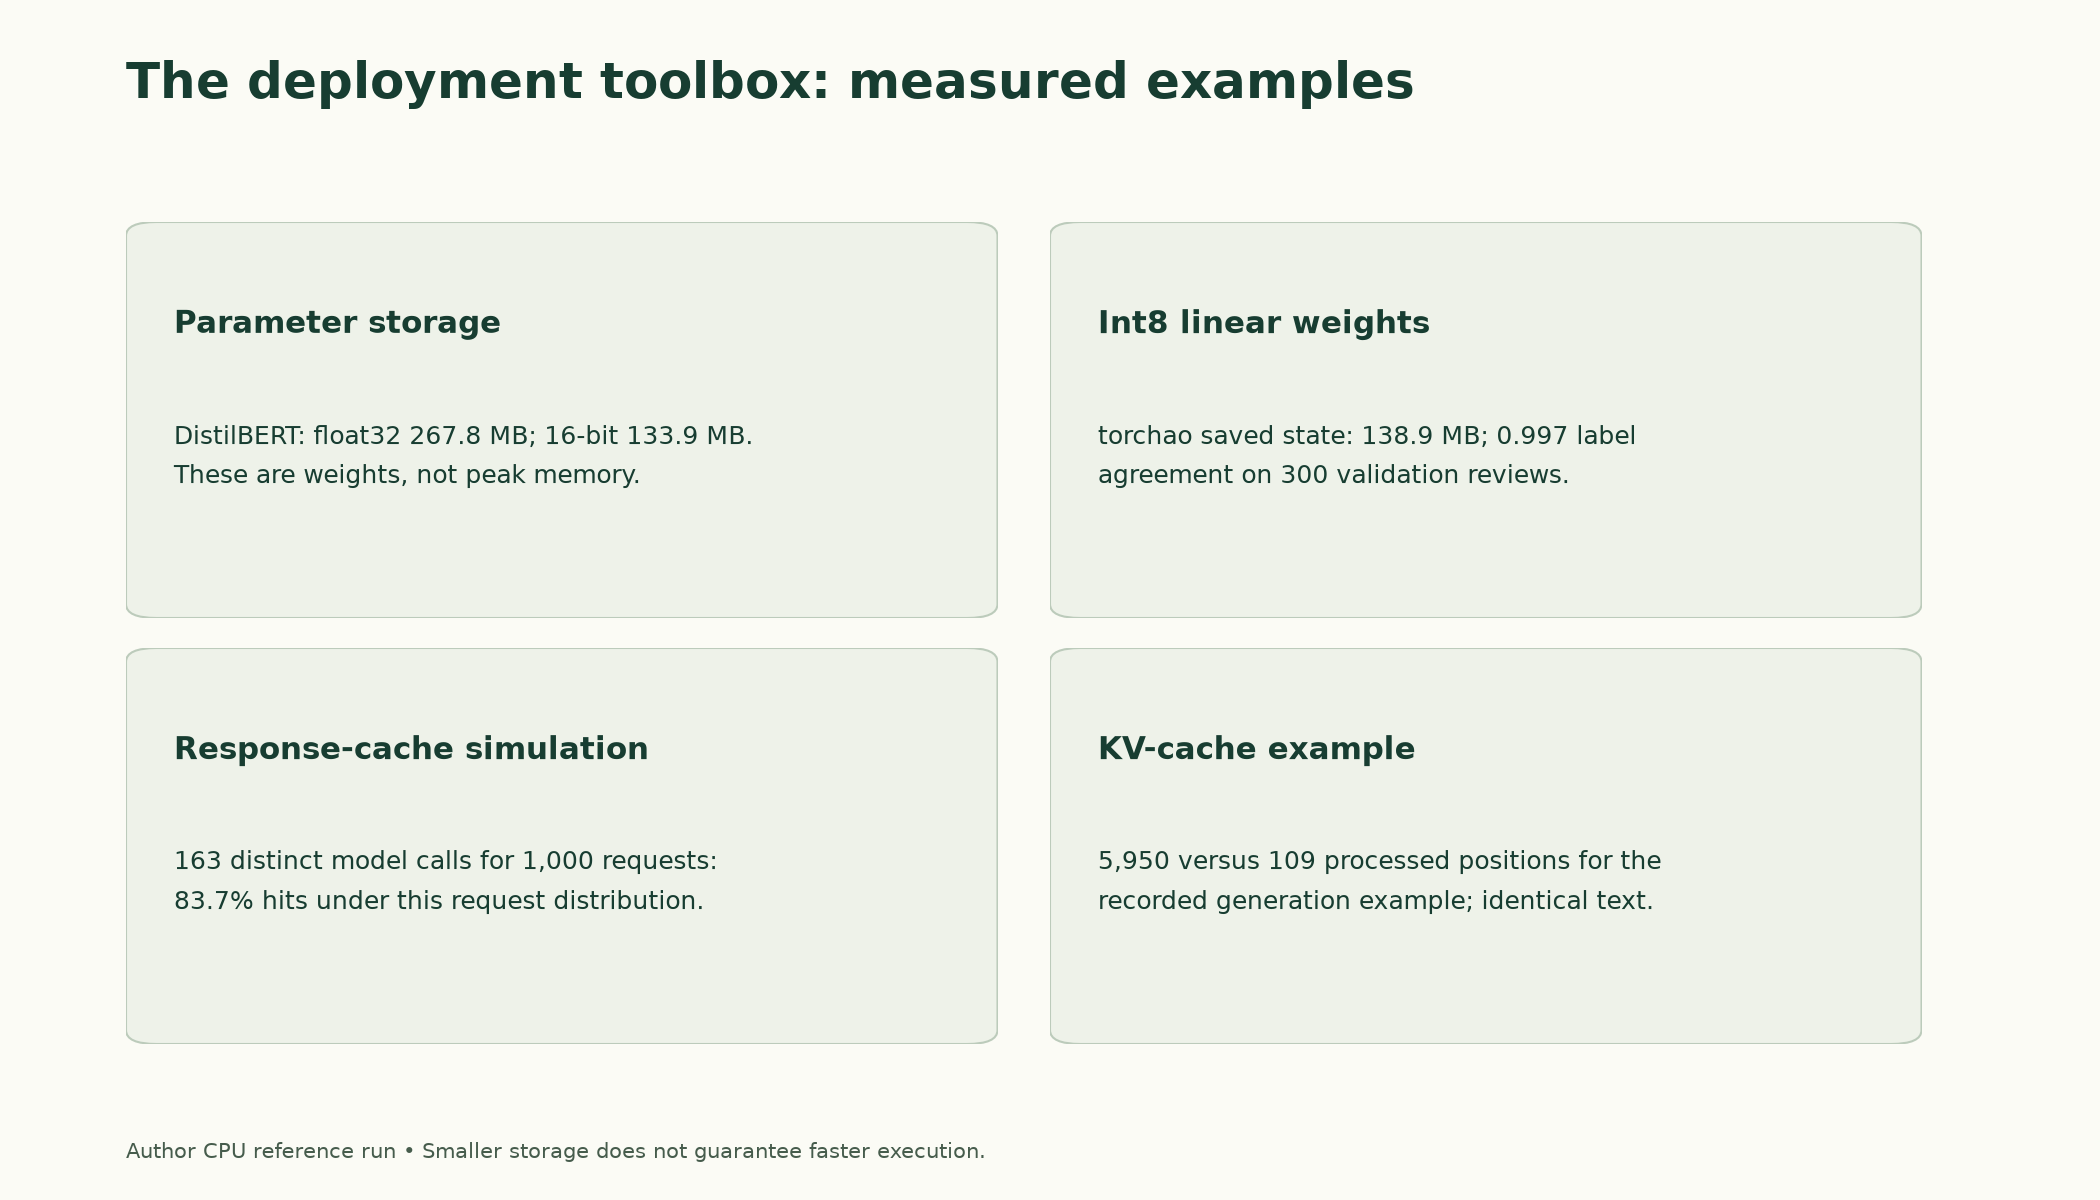

*Figure 7.6.3. Source CPU reference measurements and counts. Weight storage is not peak runtime memory, and positions processed with a KV cache are not a direct FLOP or speedup ratio.*

## Summary

- **Latency** (time per request) and **throughput** (requests per second) are different goals. Report latency percentiles such as p95, not just averages. Our latency grew in step with the number of tokens.
- **Batching** raises throughput but adds waiting time; **dynamic batching** groups requests that arrive close together. GPUs gain much more from batching than CPUs.
- **Memory = parameters × bytes**, confirmed exactly: 267.8 MB in float32 and 133.9 MB in float16 or bfloat16. bfloat16 keeps float32's range with less precision; float16 overflows above 6.55e+04.
- **Quantisation** stores weights as int8 plus a per-row scale. For DistilBERT, quantising the Linear layers gave 138.8 MB (by hand) and 138.9 MB (torchao), with 0.997 label agreement on 300 reviews. The 95.3 MB of embeddings stayed float32.
- **Smaller is not automatically faster:** on this CPU, bfloat16 and int8 were both slower than float32. Speed depends on hardware kernels.
- A **response cache** with a correct key (input, model, settings) answered 83.7% of a skewed request stream; the **KV cache** reduced generation from 5,950 to 109 processed positions with identical output.
- **Hosted vs. local** decides who owns these constraints; a break-even estimate from measured throughput guides the choice.
- **Reproducibility** needs a manifest (model commit, settings, data fingerprint, versions), deterministic eval-mode inference (batched and single runs differed by at most 1.91e-06), and pinned software.

## Glossary

| Term | Meaning |
|---|---|
| Deployment constraint | A practical limit a deployed model must meet, such as latency, memory or cost. |
| Latency | The time to serve one request. |
| Throughput | The number of requests served per second. |
| Percentile (p95) | The value below which 95% of measurements fall. |
| Dynamic batching | Grouping requests that arrive close together into one batch. |
| GPU | A processor with many parallel arithmetic units, well suited to neural networks. |
| float32 / float16 / bfloat16 | 32- and 16-bit floating-point number formats. |
| Precision | The smallest relative difference a format can represent. |
| Range | The largest magnitude a format can store before overflowing. |
| Overflow | A value too large for its format, stored as infinity. |
| Quantisation | Storing numbers with fewer bits, such as int8 integers plus a scale. |
| int8 | 8-bit integers, 1 byte each. |
| Scale | The factor converting between original values and quantised integers. |
| Per-channel quantisation | A separate scale for each row of a weight matrix. |
| Weight-only quantisation | Quantising stored weights while computing with higher-precision activations. |
| torchao | PyTorch's library for quantisation and related optimisations. |
| Kernel | A low-level routine performing an operation for specific hardware and number format. |
| Response cache | Stored answers returned directly when the same request repeats. |
| Cache key | The information identifying a cached answer: input, model version, settings. |
| Cache hit rate | The share of requests served from the cache. |
| KV cache | Stored attention keys and values for past tokens, reused during generation. |
| Self-hosting | Running a model on machines you control. |
| Break-even volume | The volume at which self-hosting and a hosted service cost the same. |
| Manifest | A record of the model version, settings, data and software behind a result. |
| Deterministic inference | Exactly the same output for the same input every time. |
| Tolerance | The allowed difference when comparing floating-point results. |